# Compress, structure, evolve: latent size and rollouts on the two-plate wake

One experiment across Stages 1–3, on their dataset (2-D flow past two collinear plates at Reynolds number 100, 1,000 snapshots of (u, v) on a 128 × 64 grid).

- **Part (a): reconstruction error against latent size.** POD, the dense autoencoder and the VAE at d = 2, 5, 10, 20, 50 (Stages 1–3 use 10), scored on the same 200 validation snapshots as the notebooks. POD is shown twice: fitted on all 1,000 snapshots, as Stages 1 and 2 do, and fitted on the 800 training snapshots only, which is the fair comparison with networks that never see the validation snapshots.
- **Part (b): multi-step rollout.** A contiguous split in time (first 800 snapshots for fitting, last 200 held out; standardisation statistics from the first 800 only). From every held-out start with 50 future snapshots, the Koopman autoencoder (encode once, apply its linear operator n times, decode) against DMD on POD coefficients of the same dimension (10), persistence and the mean flow, error against horizon n = 1 … 50; and the eigenvalue moduli of each learned operator against the unit circle.

Three seeds (0, 1, 2) for every network. Errors are the mean relative L2 error of Stages 1–3 (per velocity component, then averaged over u and v).

# Stage 4 — Latent size and rollouts: what the networks buy over POD and DMD

**Portfolio project: compress, structure and evolve one flow dataset — autoencoders, a VAE and a Koopman autoencoder.**

Stages 1–3 each compare their networks with a baseline, but in ways that flatter the networks: POD is scored on all snapshots including the ones it was fitted on, and every split is random over a time series, so each validation snapshot has its neighbours in time in the training set. Here I repeat the two central comparisons on equal terms, with three seeds per network. **Part (a)**: reconstruction error against latent size (d = 2, 5, 10, 20, 50) for POD fitted on the training snapshots only, the dense autoencoder and the VAE, all scored on the same 200 validation snapshots. **Part (b)**: a contiguous split in time (first 800 snapshots for fitting, normalisation statistics from them only), and from each of 150 held-out starts a rollout of up to 50 steps: the Koopman autoencoder against DMD on 10 POD coefficients, persistence and the mean flow, plus the eigenvalues of every learned operator against the unit circle.

**What it shows.** The autoencoders really do compress better than POD of the same size once POD is held to the same validation snapshots: at d = 10 about 0.45–0.50 against 0.757. But the Koopman autoencoder does not forecast: its error on held-out starts exceeds 1 (worse than predicting the mean flow) from the first step and grows to about 1.4 at 50 steps, while DMD stays below 1 for 20 steps, and whether its operator is stable depends on the seed.

**How it connects.** It reads the same dataset as Stages 1–3 and copies Stage 2's autoencoder and VAE builders and Stage 3's Koopman builders unchanged. The device timings it reads were measured before any training, one step of each network of the project on the CPU and on the Apple GPU.

**About the outputs.** The outputs below come from my run on 2026-10-13 (Apple M3 Max, Apple GPU). Afterwards I changed only text for this repository: this cell and the paths cell, and the path lines (dataset from `../release_assets/`, tables and figures to `../results/04_rollout_and_baselines/`, the seed-0 Koopman model to `../models/04_rollout_and_baselines/`).

In [ ]:
# Paths in the repository layout (run this notebook from notebooks/)
from pathlib import Path
DATA_FILE = Path("../release_assets/G1Re100_coarse.npz")       # release file (README)
RESULTS = Path("../results/04_rollout_and_baselines")             # also holds the device timings read below
for p in (RESULTS, Path("../models/04_rollout_and_baselines")): p.mkdir(parents=True, exist_ok=True)
print("dataset present:", DATA_FILE.exists(), "| device timings present:", (RESULTS / "device_timing_cpu.csv").exists())

In [1]:
import json, time, pathlib
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

timing = pd.concat([pd.read_csv("../results/04_rollout_and_baselines/device_timing_cpu.csv"), pd.read_csv("../results/04_rollout_and_baselines/device_timing_gpu.csv")])
tt = timing.pivot(index="network", columns="device", values="median_ms"); print(tt.round(2))
for net in ("dense AE with dropout (VAE notebook)", "dense VAE", "Koopman AE (256 hidden)"):
    assert tt.loc[net, "gpu"] < tt.loc[net, "cpu"], net
print("All three networks of this experiment train faster on the Apple GPU: GPU used.")
RES = pathlib.Path("../results/04_rollout_and_baselines"); RES.mkdir(parents=True, exist_ok=True)
MOD = pathlib.Path("../models/04_rollout_and_baselines"); MOD.mkdir(parents=True, exist_ok=True)
data = np.load("../release_assets/G1Re100_coarse.npz"); UV = data["UV"]; xx, yy = data["x"], data["y"]
n_t, n_x, n_y, n_v = UV.shape; input_shape = (n_x, n_y, n_v)
print("UV", UV.shape)

def rel_err(v_true, v_pred):
    """The metric of Stages 1-3: mean over snapshots of ||v - v_hat|| / ||v|| per component, then the mean over u and v."""
    e = np.linalg.norm(v_true - v_pred, axis=(1, 2)) / np.linalg.norm(v_true, axis=(1, 2))
    return float(np.mean(e))

device                                  cpu     gpu
network                                            
Koopman AE (256 hidden)               10.34    9.92
conv AE (32 filters, 1 block)         37.68  624.03
conv AE, 2 blocks (Ex 2)              63.53  729.16
conv VAE (Ex 4)                       37.76  625.22
dense AE (16384-512-10)               19.48    9.56
dense AE with dropout (VAE notebook)  19.85   10.98
dense VAE                             19.68   11.30
non-linear Koopman AE (Ex 1)          10.45   12.12
All three networks of this experiment train faster on the Apple GPU: GPU used.


UV (1000, 128, 64, 2)


## Part (a): reconstruction error against latent size

Same preprocessing and split as Stages 1 and 2: the time-mean field (over all snapshots) is removed, and `train_test_split(test_size=0.2, random_state=24, shuffle=True)` gives the same 800 / 200 snapshots. The dense autoencoder and the VAE are Stage 2's builders (512 hidden units, dropout 0.1; VAE with β = 1e-3, error from `z_mean`), trained with that notebook's sweep budget for both: Adam 1e-3, batch 32, at most 150 epochs, early stopping patience 15, learning-rate halving patience 6.

In [2]:
v = UV - UV.mean(axis=0)
v_trn, v_val = train_test_split(v, test_size=0.2, random_state=24, shuffle=True)
print("train", v_trn.shape, "| validation", v_val.shape)

# POD fitted on all snapshots (as the notebooks) and on the training snapshots only
U_all, s_all, vh_all = np.linalg.svd(v.reshape((n_t, -1)).T, full_matrices=False)
U_trn, s_trn, _ = np.linalg.svd(v_trn.reshape((len(v_trn), -1)).T, full_matrices=False)
def pod_val_error(U, d):
    X = v_val.reshape((len(v_val), -1)); P = U[:, :d]
    return rel_err(v_val, (X @ P @ P.T).reshape(v_val.shape))
def pod_all_error(d):   # the POD number of Stages 1 and 2: reconstruction of all 1,000 snapshots with the all-snapshot basis
    vp = (U_all[:, :d] @ np.diag(s_all[:d]) @ vh_all[:d]).T.reshape(v.shape); return rel_err(v, vp)
SIZES = (2, 5, 10, 20, 50)
pod_rows = [dict(d=d, pod_all_snapshots_notebook=pod_all_error(d), pod_all_basis_on_val=pod_val_error(U_all, d), pod_train_basis_on_val=pod_val_error(U_trn, d)) for d in SIZES]
pod_tab = pd.DataFrame(pod_rows); pod_tab.to_csv(RES / "a_pod.csv", index=False); print(pod_tab.round(4).to_string(index=False))

train (800, 128, 64, 2) | validation (200, 128, 64, 2)


 d  pod_all_snapshots_notebook  pod_all_basis_on_val  pod_train_basis_on_val
 2                      0.9218                0.9161                  0.9184
 5                      0.8370                0.8285                  0.8341
10                      0.7483                0.7408                  0.7572
20                      0.6040                0.5933                  0.6139
50                      0.3924                0.3851                  0.4168


In [3]:
# Stage 2's builders (Sections 5 and 11), copied unchanged
def create_dense_encoder(input_shape, latent_dim, hidden_units=512, activation="relu", dropout_rate=0.1):
    inputs = tf.keras.layers.Input(shape=input_shape)
    x = tf.keras.layers.Flatten()(inputs)
    x = tf.keras.layers.Dense(hidden_units, activation=activation)(x)
    x = tf.keras.layers.Dropout(dropout_rate)(x)
    latent = tf.keras.layers.Dense(latent_dim)(x)
    return tf.keras.Model(inputs, latent, name="dense_encoder")

def create_dense_decoder(output_shape, latent_dim, hidden_units=512, activation="relu", dropout_rate=0.1):
    n_x, n_y, n_v = output_shape
    latent_inputs = tf.keras.layers.Input(shape=(latent_dim,))
    x = tf.keras.layers.Dense(hidden_units, activation=activation)(latent_inputs)
    x = tf.keras.layers.Dropout(dropout_rate)(x)
    x = tf.keras.layers.Dense(n_x * n_y * n_v)(x)
    outputs = tf.keras.layers.Reshape(output_shape)(x)
    return tf.keras.Model(latent_inputs, outputs, name="dense_decoder")

class Sampling(tf.keras.layers.Layer):
    def call(self, inputs):
        z_mean, z_log_var = inputs
        epsilon = tf.keras.backend.random_normal(shape=(tf.shape(z_mean)[0], tf.shape(z_mean)[1]))
        return z_mean + tf.exp(0.5 * z_log_var) * epsilon

def create_vae_encoder(input_shape, latent_dim, hidden_units=512, dropout_rate=0.1, activation="relu"):
    inputs = tf.keras.layers.Input(shape=input_shape)
    x = tf.keras.layers.Flatten()(inputs)
    x = tf.keras.layers.Dense(hidden_units, activation=activation)(x)
    x = tf.keras.layers.Dropout(dropout_rate)(x)
    z_mean = tf.keras.layers.Dense(latent_dim, name="z_mean")(x)
    z_log_var = tf.keras.layers.Dense(latent_dim, name="z_log_var")(x)
    z = Sampling()([z_mean, z_log_var])
    return tf.keras.Model(inputs, [z_mean, z_log_var, z], name="vae_encoder")

class VAE(tf.keras.Model):
    def __init__(self, encoder, decoder, beta=1.0, **kwargs):
        super().__init__(**kwargs)
        self.encoder, self.decoder, self.beta = encoder, decoder, beta
        self.total_loss_tracker = tf.keras.metrics.Mean(name="loss")
        self.reconstruction_loss_tracker = tf.keras.metrics.Mean(name="reconstruction_loss")
        self.kl_loss_tracker = tf.keras.metrics.Mean(name="kl_loss")
    @property
    def metrics(self):
        return [self.total_loss_tracker, self.reconstruction_loss_tracker, self.kl_loss_tracker]
    def call(self, inputs):
        z_mean, z_log_var, z = self.encoder(inputs)
        return self.decoder(z)
    def _vae_losses(self, x, y):
        z_mean, z_log_var, z = self.encoder(x)
        reconstruction = self.decoder(z)
        rec = tf.reduce_mean(tf.reduce_sum(tf.square(y - reconstruction), axis=[1, 2, 3]))
        kl = tf.reduce_mean(tf.reduce_sum(-0.5 * (1 + z_log_var - tf.square(z_mean) - tf.exp(z_log_var)), axis=1))
        return rec, kl, rec + self.beta * kl
    def train_step(self, data):
        x, y = data
        with tf.GradientTape() as tape:
            rec, kl, total = self._vae_losses(x, y)
        grads = tape.gradient(total, self.trainable_weights)
        self.optimizer.apply_gradients(zip(grads, self.trainable_weights))
        for m, val in zip(self.metrics, (total, rec, kl)): m.update_state(val)
        return {m.name: m.result() for m in self.metrics}
    def test_step(self, data):
        x, y = data
        rec, kl, total = self._vae_losses(x, y)
        for m, val in zip(self.metrics, (total, rec, kl)): m.update_state(val)
        return {m.name: m.result() for m in self.metrics}

def sweep_cbs():
    return [tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=15, restore_best_weights=True),
            tf.keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=6, min_lr=1e-6)]

a_rows = []
def run_a(seed):
    for d in SIZES:
        tf.keras.backend.clear_session(); tf.keras.utils.set_random_seed(seed)
        enc, dec = create_dense_encoder(input_shape, d), create_dense_decoder(input_shape, d)
        i = tf.keras.layers.Input(shape=input_shape); ae = tf.keras.Model(i, dec(enc(i)))
        ae.compile(optimizer=tf.keras.optimizers.Adam(1e-3), loss="mse"); t0 = time.perf_counter()
        h = ae.fit(v_trn, v_trn, validation_data=(v_val, v_val), epochs=150, batch_size=32, verbose=0, callbacks=sweep_cbs())
        a_rows.append(dict(model="dense AE", d=d, seed=seed, rel_error=rel_err(v_val, ae.predict(v_val, verbose=0)), epochs=len(h.history["loss"]), train_s=round(time.perf_counter() - t0, 1)))
        print(a_rows[-1], flush=True)
        tf.keras.backend.clear_session(); tf.keras.utils.set_random_seed(seed)
        venc, vdec = create_vae_encoder(input_shape, d), create_dense_decoder(input_shape, d)
        vae = VAE(venc, vdec, beta=1e-3); vae.compile(optimizer=tf.keras.optimizers.Adam(1e-3)); t0 = time.perf_counter()
        h = vae.fit(v_trn, v_trn, validation_data=(v_val, v_val), epochs=150, batch_size=32, verbose=0, callbacks=sweep_cbs())
        zm = venc.predict(v_val, verbose=0)[0]
        a_rows.append(dict(model="VAE", d=d, seed=seed, rel_error=rel_err(v_val, vdec.predict(zm, verbose=0)), epochs=len(h.history["loss"]), train_s=round(time.perf_counter() - t0, 1)))
        print(a_rows[-1], flush=True)

In [4]:
run_a(0)  # seed 0

2026-10-13 19:07:03.499757: I metal_plugin/src/device/metal_device.cc:1154] Metal device set to: Apple M3 Max
2026-10-13 19:07:03.499782: I metal_plugin/src/device/metal_device.cc:296] systemMemory: 48.00 GB
2026-10-13 19:07:03.499788: I metal_plugin/src/device/metal_device.cc:313] maxCacheSize: 18.72 GB
I0000 00:00:1791932823.499800 50909287 pluggable_device_factory.cc:305] Could not identify NUMA node of platform GPU ID 0, defaulting to 0. Your kernel may not have been built with NUMA support.
I0000 00:00:1791932823.499816 50909287 pluggable_device_factory.cc:271] Created TensorFlow device (/job:localhost/replica:0/task:0/device:GPU:0 with 0 MB memory) -> physical PluggableDevice (device: 0, name: METAL, pci bus id: <undefined>)


2026-10-13 19:07:03.841192: I tensorflow/core/grappler/optimizers/custom_graph_optimizer_registry.cc:117] Plugin optimizer for device_type GPU is enabled.


{'model': 'dense AE', 'd': 2, 'seed': 0, 'rel_error': 0.8985780726727427, 'epochs': 67, 'train_s': 20.6}


{'model': 'VAE', 'd': 2, 'seed': 0, 'rel_error': 0.9081038705614694, 'epochs': 45, 'train_s': 15.8}


{'model': 'dense AE', 'd': 5, 'seed': 0, 'rel_error': 0.7636702483369849, 'epochs': 85, 'train_s': 25.9}


...

{'model': 'VAE', 'd': 10, 'seed': 0, 'rel_error': 0.4642161384130614, 'epochs': 150, 'train_s': 51.5}


{'model': 'dense AE', 'd': 20, 'seed': 0, 'rel_error': 0.3629854554508665, 'epochs': 88, 'train_s': 27.1}


{'model': 'VAE', 'd': 20, 'seed': 0, 'rel_error': 0.30410104910455255, 'epochs': 150, 'train_s': 53.2}


{'model': 'dense AE', 'd': 50, 'seed': 0, 'rel_error': 0.2959676471685645, 'epochs': 108, 'train_s': 39.0}


{'model': 'VAE', 'd': 50, 'seed': 0, 'rel_error': 0.2648858974669866, 'epochs': 150, 'train_s': 52.8}


In [5]:
run_a(1)  # seed 1

{'model': 'dense AE', 'd': 2, 'seed': 1, 'rel_error': 0.8936542493486275, 'epochs': 77, 'train_s': 24.7}


{'model': 'VAE', 'd': 2, 'seed': 1, 'rel_error': 0.8918282497593566, 'epochs': 108, 'train_s': 37.4}


{'model': 'dense AE', 'd': 5, 'seed': 1, 'rel_error': 0.7601985703567854, 'epochs': 103, 'train_s': 31.8}


{'model': 'VAE', 'd': 5, 'seed': 1, 'rel_error': 0.7485884250097296, 'epochs': 112, 'train_s': 39.3}


{'model': 'dense AE', 'd': 10, 'seed': 1, 'rel_error': 0.5130677240866252, 'epochs': 97, 'train_s': 30.0}


{'model': 'VAE', 'd': 10, 'seed': 1, 'rel_error': 0.4429246793302951, 'epochs': 150, 'train_s': 52.4}


{'model': 'dense AE', 'd': 20, 'seed': 1, 'rel_error': 0.3520117422344135, 'epochs': 110, 'train_s': 34.1}


{'model': 'VAE', 'd': 20, 'seed': 1, 'rel_error': 0.3035878222482187, 'epochs': 150, 'train_s': 52.1}


{'model': 'dense AE', 'd': 50, 'seed': 1, 'rel_error': 0.29513663552699887, 'epochs': 97, 'train_s': 29.8}


{'model': 'VAE', 'd': 50, 'seed': 1, 'rel_error': 0.4062963208605474, 'epochs': 31, 'train_s': 11.7}


In [6]:
run_a(2)  # seed 2

{'model': 'dense AE', 'd': 2, 'seed': 2, 'rel_error': 0.9126381533749851, 'epochs': 54, 'train_s': 17.1}


{'model': 'VAE', 'd': 2, 'seed': 2, 'rel_error': 0.8917605020126195, 'epochs': 77, 'train_s': 27.2}


{'model': 'dense AE', 'd': 5, 'seed': 2, 'rel_error': 0.769379710838944, 'epochs': 73, 'train_s': 22.9}


{'model': 'VAE', 'd': 5, 'seed': 2, 'rel_error': 0.7621182150049001, 'epochs': 76, 'train_s': 26.9}


{'model': 'dense AE', 'd': 10, 'seed': 2, 'rel_error': 0.4785584896287588, 'epochs': 131, 'train_s': 40.1}


{'model': 'VAE', 'd': 10, 'seed': 2, 'rel_error': 0.43605624734778314, 'epochs': 150, 'train_s': 52.5}


{'model': 'dense AE', 'd': 20, 'seed': 2, 'rel_error': 0.3569293923873956, 'epochs': 98, 'train_s': 31.0}


{'model': 'VAE', 'd': 20, 'seed': 2, 'rel_error': 0.3110384861311966, 'epochs': 150, 'train_s': 52.5}


{'model': 'dense AE', 'd': 50, 'seed': 2, 'rel_error': 0.29836412587437133, 'epochs': 93, 'train_s': 29.4}


{'model': 'VAE', 'd': 50, 'seed': 2, 'rel_error': 0.26728079188098336, 'epochs': 150, 'train_s': 54.6}


    POD, all snapshots (Stages 1 and 2)  POD, training basis, validation  dense AE (mean of 3)  VAE (mean of 3)
d                                                                                                         
2                           0.9218                           0.9184                0.9016           0.8972
5                           0.8370                           0.8341                0.7644           0.7531
10                          0.7483                           0.7572                0.4992           0.4477
20                          0.6040                           0.6139                0.3573           0.3062
50                          0.3924                           0.4168                0.2965           0.3128


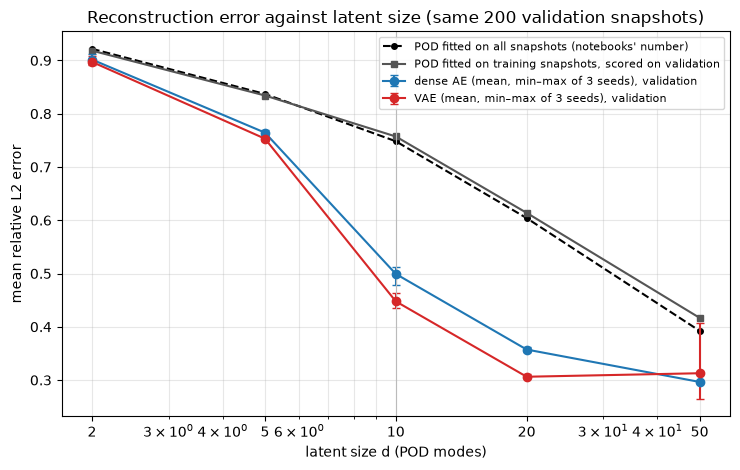

In [7]:
a = pd.DataFrame(a_rows); a.to_csv(RES / "a_runs.csv", index=False)
a_sum = a.groupby(["model", "d"]).rel_error.agg(["mean", "std", "min", "max"]).reset_index(); a_sum.to_csv(RES / "a_summary.csv", index=False)
tab = pod_tab.set_index("d")[["pod_all_snapshots_notebook", "pod_train_basis_on_val"]].join(a_sum.pivot(index="d", columns="model", values="mean")[["dense AE", "VAE"]])
tab.columns = ["POD, all snapshots (Stages 1 and 2)", "POD, training basis, validation", "dense AE (mean of 3)", "VAE (mean of 3)"]
tab.to_csv(RES / "a_table.csv"); print(tab.round(4).to_string())
fig, ax = plt.subplots(figsize=(7.5, 4.8))
ax.plot(SIZES, pod_tab.pod_all_snapshots_notebook, "k--o", ms=4, label="POD fitted on all snapshots (Stages 1 and 2)")
ax.plot(SIZES, pod_tab.pod_train_basis_on_val, "-s", color="#555", ms=5, label="POD fitted on training snapshots, scored on validation")
for m, c in (("dense AE", "#1f77b4"), ("VAE", "#d62728")):
    r = a_sum[a_sum.model == m]
    ax.errorbar(r.d, r["mean"], yerr=[r["mean"] - r["min"], r["max"] - r["mean"]], marker="o", capsize=3, color=c, label=f"{m} (mean, min–max of 3 seeds), validation")
ax.set_xscale("log"); ax.set_xticks(SIZES); ax.set_xticklabels([str(d) for d in SIZES]); ax.axvline(10, color="#bbb", lw=0.8)
ax.set_xlabel("latent size d (POD modes)"); ax.set_ylabel("mean relative L2 error"); ax.grid(alpha=0.3, which="both"); ax.legend(fontsize=8)
ax.set_title("Reconstruction error against latent size (same 200 validation snapshots)")
fig.tight_layout(); fig.savefig(RES / "a_latent_size.png", dpi=130); plt.show()

## Part (b): multi-step rollout from held-out starts

A contiguous split in time: the first 800 snapshots are the fitting period, the last 200 are held out. As in Stage 3, each snapshot is standardised point by point (mean and standard deviation over time), but here those statistics come from the fitting period only. The Koopman autoencoder is Stage 3's `create_koopman_autoencoder` (256 hidden units, d = 10, a linear operator without bias, two equally weighted MSE terms), fitted on the 799 consecutive pairs of the fitting period with a random 15 % of them used for early stopping (patience 20, learning-rate halving patience 8, at most 600 epochs). DMD: POD basis of rank 10 from the fitting-period snapshots, operator by least squares on the same pairs. Every held-out snapshot with 50 future snapshots is a start (150 starts).

In [8]:
cut, H = 800, 50
mu, sd = UV[:cut].mean(axis=0), UV[:cut].std(axis=0) + 1e-8
w = (UV - mu) / sd
Xa, ya = w[:cut - 1], w[1:cut]
Xt, Xv, yt, yv = train_test_split(Xa, ya, test_size=0.15, random_state=24, shuffle=True)
starts = np.arange(cut, n_t - H)
print("fitting pairs", len(Xa), "(early-stopping pairs", len(Xv), ") | held-out starts", len(starts), "| horizon", H)

# DMD on POD coefficients (rank 10), fitted on the fitting period
d_dmd = 10
U_f, _, _ = np.linalg.svd(w[:cut].reshape((cut, -1)).T, full_matrices=False); Phi = U_f[:, :d_dmd]
A_dmd, *_ = np.linalg.lstsq(Xa.reshape((len(Xa), -1)) @ Phi, ya.reshape((len(ya), -1)) @ Phi, rcond=None)
eig_dmd = np.linalg.eigvals(A_dmd.T)
b_rows = []
a_c = w[starts].reshape((len(starts), -1)) @ Phi
for n in range(1, H + 1):
    a_c = a_c @ A_dmd; truth = w[starts + n]
    b_rows.append(dict(model="DMD (POD rank 10)", seed=-1, n=n, rel_error=rel_err(truth, (a_c @ Phi.T).reshape(truth.shape))))
    b_rows.append(dict(model="persistence", seed=-1, n=n, rel_error=rel_err(truth, w[starts])))
    b_rows.append(dict(model="mean flow (zero fluctuation)", seed=-1, n=n, rel_error=rel_err(truth, np.zeros_like(truth))))
print("DMD |eigenvalues|:", np.round(np.sort(np.abs(eig_dmd))[::-1], 4))

fitting pairs 799 (early-stopping pairs 120 ) | held-out starts 150 | horizon 50


DMD |eigenvalues|: [0.9978 0.9978 0.9961 0.9961 0.9929 0.9929 0.9893 0.9893 0.9875 0.9875]


In [9]:
# Stage 3's builders (Sections 5 and 7), copied unchanged
def k_dense_encoder(input_shape, latent_dim, hidden_units=512, activation="relu"):
    inputs = tf.keras.layers.Input(shape=input_shape)
    x = tf.keras.layers.Flatten()(inputs)
    x = tf.keras.layers.Dense(hidden_units, activation=activation)(x)
    return tf.keras.Model(inputs, tf.keras.layers.Dense(latent_dim)(x), name="dense_encoder")

def k_dense_decoder(output_shape, latent_dim, hidden_units=512, activation="relu"):
    n_x, n_y, n_v = output_shape
    latent_inputs = tf.keras.layers.Input(shape=(latent_dim,))
    x = tf.keras.layers.Dense(hidden_units, activation=activation)(latent_inputs)
    x = tf.keras.layers.Dense(n_x * n_y * n_v)(x)
    return tf.keras.Model(latent_inputs, tf.keras.layers.Reshape(output_shape)(x), name="dense_decoder")

def create_koopman_operator(latent_dim):
    latent_inputs = tf.keras.layers.Input(shape=(latent_dim,))
    return tf.keras.Model(latent_inputs, tf.keras.layers.Dense(latent_dim, use_bias=False, name="A")(latent_inputs), name="koopman_operator")

def create_koopman_autoencoder(input_shape, latent_dim, hidden_units=256, activation="relu", learning_rate=1e-3):
    encoder = k_dense_encoder(input_shape, latent_dim=latent_dim, hidden_units=hidden_units, activation=activation)
    koopman_operator = create_koopman_operator(latent_dim)
    decoder = k_dense_decoder(input_shape, latent_dim=latent_dim, hidden_units=hidden_units, activation=activation)
    inputs = tf.keras.layers.Input(shape=input_shape)
    encoded = encoder(inputs)
    model = tf.keras.Model(inputs, [decoder(encoded), decoder(koopman_operator(encoded))], name="Koopman_Autoencoder")
    model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=learning_rate), loss=["mse", "mse"], loss_weights=[1.0, 1.0])
    return model, encoder, koopman_operator, decoder

eig_rows, k_info = [], []
def run_b(seed):
    tf.keras.backend.clear_session(); tf.keras.utils.set_random_seed(seed)
    m, enc, op, dec = create_koopman_autoencoder(input_shape, 10); t0 = time.perf_counter()
    h = m.fit(Xt, [Xt, yt], validation_data=(Xv, [Xv, yv]), epochs=600, batch_size=32, verbose=0,
              callbacks=[tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=20, restore_best_weights=True),
                         tf.keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=8, min_lr=1e-6)])
    k_info.append(dict(seed=seed, epochs=len(h.history["loss"]), train_s=round(time.perf_counter() - t0, 1)))
    A = op.get_layer("A").get_weights()[0]; lam = np.linalg.eigvals(A.T)
    eig_rows.extend(dict(operator="Koopman AE", seed=seed, re=float(l.real), im=float(l.imag), modulus=float(abs(l))) for l in lam)
    z = enc.predict(w[starts], verbose=0)
    for n in range(1, H + 1):
        z = z @ A; truth = w[starts + n]
        b_rows.append(dict(model="Koopman AE", seed=seed, n=n, rel_error=rel_err(truth, dec.predict(z, verbose=0))))
    if seed == 0:
        m.save(MOD / "koopman_ae_contiguous_seed0.keras")
    print(k_info[-1], "max |lambda|", round(float(np.abs(lam).max()), 4), "| n=1 / 10 / 50:", [round(r["rel_error"], 4) for r in b_rows if r["model"] == "Koopman AE" and r["seed"] == seed and r["n"] in (1, 10, 50)], flush=True)

In [10]:
run_b(0)  # seed 0

{'seed': 0, 'epochs': 216, 'train_s': 63.8} max |lambda| 0.9895 | n=1 / 10 / 50: [1.0152, 1.1183, 1.0755]


In [11]:
run_b(1)  # seed 1

{'seed': 1, 'epochs': 231, 'train_s': 67.8} max |lambda| 1.0163 | n=1 / 10 / 50: [1.0258, 1.5085, 1.4938]


In [12]:
run_b(2)  # seed 2

{'seed': 2, 'epochs': 187, 'train_s': 55.1} max |lambda| 1.0107 | n=1 / 10 / 50: [0.9992, 1.2689, 1.7002]


Mean relative error at n steps ahead (Koopman AE: mean of 3 seeds):
n                                 1       2       5       10      20      50
model                                                                       
DMD (POD rank 10)             0.8334  0.8399  0.8666  0.9127  0.9764  1.0963
Koopman AE                    1.0134  1.2293  1.2673  1.2986  1.3694  1.4232
mean flow (zero fluctuation)  1.0000  1.0000  1.0000  1.0000  1.0000  1.0000
persistence                   0.4006  0.7327  1.3050  1.5867  1.2061  1.3366
         operator  seed  max_modulus  n_outside  n_on  n_inside
DMD (POD rank 10)    -1     0.997830          0     0        10
       Koopman AE     0     0.989513          0     0        10
       Koopman AE     1     1.016349          2     0         8
       Koopman AE     2     1.010707          1     0         9


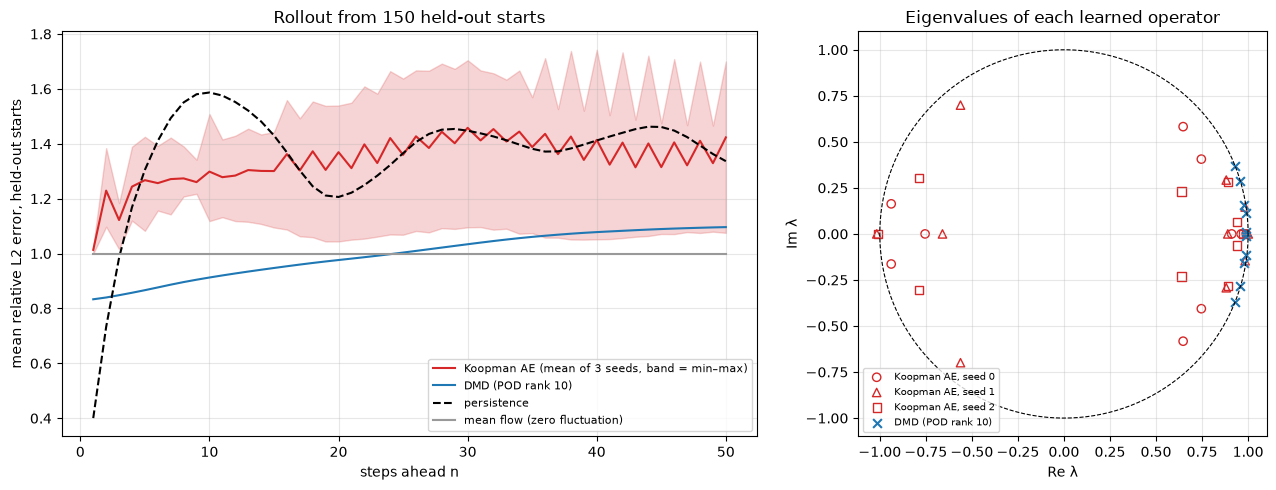

In [13]:
eig_rows += [dict(operator="DMD (POD rank 10)", seed=-1, re=float(l.real), im=float(l.imag), modulus=float(abs(l))) for l in eig_dmd]
b = pd.DataFrame(b_rows); b.to_csv(RES / "b_rollout_runs.csv", index=False)
eig = pd.DataFrame(eig_rows); eig["position"] = np.where(eig.modulus > 1.001, "outside", np.where(eig.modulus >= 0.999, "on (within 0.001)", "inside")); eig.to_csv(RES / "b_eigenvalues.csv", index=False)
pd.DataFrame(k_info).to_csv(RES / "b_koopman_training.csv", index=False)
bs = b.groupby(["model", "n"]).rel_error.agg(["mean", "min", "max"]).reset_index(); bs.to_csv(RES / "b_rollout_summary.csv", index=False)
NS = (1, 2, 5, 10, 20, 50)
tab_b = bs[bs.n.isin(NS)].pivot(index="model", columns="n", values="mean"); tab_b.to_csv(RES / "b_table.csv")
print("Mean relative error at n steps ahead (Koopman AE: mean of 3 seeds):"); print(tab_b.round(4).to_string())
ek = eig.groupby(["operator", "seed"]).agg(max_modulus=("modulus", "max"), n_outside=("position", lambda s: int((s == "outside").sum())),
                                            n_on=("position", lambda s: int((s == "on (within 0.001)").sum())), n_inside=("position", lambda s: int((s == "inside").sum()))).reset_index()
ek.to_csv(RES / "b_eigen_summary.csv", index=False); print(ek.to_string(index=False))

fig, ax = plt.subplots(1, 2, figsize=(13, 5), gridspec_kw=dict(width_ratios=[1.6, 1]))
cols = {"Koopman AE": "#d62728", "DMD (POD rank 10)": "#1f77b4", "persistence": "k", "mean flow (zero fluctuation)": "#999"}
for mname, c in cols.items():
    r = bs[bs.model == mname]
    ax[0].plot(r.n, r["mean"], "-" if mname != "persistence" else "--", color=c, label=mname + (" (mean of 3 seeds, band = min–max)" if mname == "Koopman AE" else ""))
    if mname == "Koopman AE": ax[0].fill_between(r.n, r["min"], r["max"], color=c, alpha=0.2)
ax[0].set_xlabel("steps ahead n"); ax[0].set_ylabel("mean relative L2 error, held-out starts"); ax[0].grid(alpha=0.3); ax[0].legend(fontsize=8)
ax[0].set_title(f"Rollout from {len(starts)} held-out starts")
th = np.linspace(0, 2 * np.pi, 300); ax[1].plot(np.cos(th), np.sin(th), "k--", lw=0.8)
for s_, mk in ((0, "o"), (1, "^"), (2, "s")):
    e_ = eig[(eig.operator == "Koopman AE") & (eig.seed == s_)]; ax[1].scatter(e_.re, e_.im, marker=mk, s=36, facecolors="none", edgecolors="#d62728", label=f"Koopman AE, seed {s_}")
e_ = eig[eig.operator == "DMD (POD rank 10)"]; ax[1].scatter(e_.re, e_.im, marker="x", s=40, color="#1f77b4", label="DMD (POD rank 10)")
ax[1].set_aspect("equal"); ax[1].grid(alpha=0.3); ax[1].legend(fontsize=7, loc="lower left"); ax[1].set_xlabel("Re λ"); ax[1].set_ylabel("Im λ"); ax[1].set_title("Eigenvalues of each learned operator")
fig.tight_layout(); fig.savefig(RES / "b_rollout_eigenvalues.png", dpi=130); plt.show()